# Inspección de Data Products en Hogwarts
### Informe del Ministerio de Magia sobre evaluación trimestral

- **Asignatura:** Programación y entornos de trabajo para la IA
- **Estudiante:** Tania Évora Vargas Martínez
- **Módulo:** Python - Unidad Didáctica 1, 2 y 3
- **Universidad:** Alfonso X el Sabio
- **Fecha:** Noviembre 2025

Este informe analiza la evolución y calidad de los Data Products registrados en Hogwarts durante los tres trimestres del año 2024, con el fin de evaluar su estado y distribución por dominios y funcionarios.

## Procesamiento y preparación de Datos
En esta primera parte se realiza todo el trabajo necesario para dejar los datos preparados para el análisis. Aquí se documentan las transformaciones, comprobaciones y limpiezas realizadas sobre los datasets trimestrales proporcionados por el Ministerio de Magia. Las tareas incluyen:
- Verificación del esquema de columnas.
- Revisión del tipo de datos y su consistencia.
- Comprobación de formato en campos especiales como *ID*, *Name*, *Status*, *Version* y *NumberUsers*.
- Creación de columnas temporales (año y trimestre).
- Unión de los tres trimestres en un único DataFrame.

Esta preparación permite que el análisis sea fiable y consistente con las reglas establecidas por el Ministerio.

In [115]:
# Librerías para el procesamiento de datos
import pandas as pd
import numpy as np
import re

### 1. Carga de datos
Se importan los tres datasets correspondientes al año 2024, cada uno con la información trimestral sobre los Data Products en Hogwarts. 

Tras la carga inicial, se verifica que las columnas de los tres trimestres coinciden con el esquema oficial definido en el enunciado (`ID`, `Name`, `Descriptive Name`, `Description`, `Domain`, `Owner`, `IsCompliance`, `Status`, `Version`, `NumberUsers`). 

Este paso garantiza que los datasets son compatibles entre sí y pueden trabajarse en un único conjunto para su posterior análisis.


In [116]:
base = "Hogwards - 2024xT"

trim1_2024 = pd.read_csv(f"{base}\Hogwards - 20241T.csv")
trim2_2024 = pd.read_csv(f"{base}\Hogwards - 20242T.csv")
trim3_2024 = pd.read_csv(f"{base}\Hogwards - 20243T.csv")

In [117]:
# Comprobación de columnas esperadas
expected_cols = ["ID", "Name", "Descriptive Name", "Description", "Domain", "Owner", "IsCompliance", "Status", "Version", "NumberUsers"]

for df in [trim1_2024, trim2_2024, trim3_2024]:
  if df.columns.tolist() != expected_cols:
    print("Las columnas no coinciden con las esperadas.")
  else:
    print("Las columnas coinciden con las esperadas.")

Las columnas coinciden con las esperadas.
Las columnas coinciden con las esperadas.
Las columnas coinciden con las esperadas.


### 2. Revisión del esquema
A continuación se comprueba la estructura de cada dataset. Esto permite:
- Confirmar que las columnas tienen tipos de datos esperados.
- Verificar que no existen valores nulos.
- Comprobar la consistencia entre los tres datasets.

La columna *IsCompliance* aparece correctamente como booleana y *NumberUsers* como entero, mientras que el resto de campos que son de texto se representan como `object`, lo cual es apropiado.

In [118]:
trim1_2024.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   ID                50 non-null     object
 1   Name              50 non-null     object
 2   Descriptive Name  50 non-null     object
 3   Description       50 non-null     object
 4   Domain            50 non-null     object
 5   Owner             50 non-null     object
 6   IsCompliance      50 non-null     bool  
 7   Status            50 non-null     object
 8   Version           50 non-null     object
 9   NumberUsers       50 non-null     int64 
dtypes: bool(1), int64(1), object(8)
memory usage: 3.7+ KB


In [119]:
trim2_2024.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70 entries, 0 to 69
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   ID                70 non-null     object
 1   Name              70 non-null     object
 2   Descriptive Name  70 non-null     object
 3   Description       70 non-null     object
 4   Domain            70 non-null     object
 5   Owner             70 non-null     object
 6   IsCompliance      70 non-null     bool  
 7   Status            70 non-null     object
 8   Version           70 non-null     object
 9   NumberUsers       70 non-null     int64 
dtypes: bool(1), int64(1), object(8)
memory usage: 5.1+ KB


In [120]:
trim3_2024.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87 entries, 0 to 86
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   ID                87 non-null     object
 1   Name              87 non-null     object
 2   Descriptive Name  87 non-null     object
 3   Description       87 non-null     object
 4   Domain            87 non-null     object
 5   Owner             87 non-null     object
 6   IsCompliance      87 non-null     bool  
 7   Status            87 non-null     object
 8   Version           87 non-null     object
 9   NumberUsers       87 non-null     int64 
dtypes: bool(1), int64(1), object(8)
memory usage: 6.3+ KB


### 3. Validación de formatos y valores esperados
El enunciado define reglas concretas sobre el formato y valores permitidos en ciertas columnas (ID, Name, Status, Version y NumberUsers). Para asegurar que los datos cumplen estas reglas, se implementa una función de validación que revisa:
- **ID:** Es único, y sigue el patrón `DPXXX` con X entre 0 y 9.
- **Name:** No debe contener espacios.
- **Status:** Debe ser uno de los cuatro estados oficiales.
- **Version:** Debe seguir el formato `X.X.X`
- **NumberUsers:** Debe estar entre 0 y 100.

Este proceso no corrige valores, únicamente detecta posibles inconsistencias, evitando modificaciones que puedan alterar el significado del dataset del Ministerio.

In [121]:
def format_check(df):
  # ID
  duplicated = df['ID'].duplicated().sum()
  if duplicated > 0:
    print(f"Hay {duplicated} IDs duplicados.")
  for id in df['ID']:
    if not re.match(r'^DP\d{3}$', id):
      print(f"ID inválido encontrado: {id}")
  # Name
  for name in df['Name']:
    if re.search(r"\s", name):
      print(f"Nombre inválido encontrado: {name}")
  # Status
  for status in df['Status']:
    if status not in ['Development', 'Planned', 'Production', 'Deprecated']:
      print(f"Status inválido encontrado: {status}")
  # Version
  for version in df['Version']:
    if not re.match(r'^\d\.\d\.\d$', str(version)):
      print(f"Version inválido encontrado: {version}")
  # NumberUsers
  for users in df['NumberUsers']:
    if not (0 <= users <= 100):
      print(f"NumberUsers inválido encontrado: {users}")
  print("Formato verificado")

format_check(trim1_2024)
format_check(trim2_2024)
format_check(trim3_2024)

Formato verificado
Formato verificado
Formato verificado


### 4. Creación de columnas temporales: Year y Trimester
Dado que los datos provienen de los tres trimestres del 2024 y la idea es unirlos, se añaden dos columnas nuevas a cada dataset:
- **Year:** Año del dataset (en este caso 2024).
- **Trimester:** Trimestre al que pertenece el registro (1, 2 o 3).

Estas columnas permiten, tras la unión de los tres datasets:
- Realizar análisis temporales.
- Generar visualizaciones de evolución trimestral.
- Ordenar y agrupar los Data Products en el tiempo.

In [122]:
trim1_2024["Year"] = 2024
trim2_2024["Year"] = 2024
trim3_2024["Year"] = 2024

trim1_2024["Trimester"] = 1
trim2_2024["Trimester"] = 2
trim3_2024["Trimester"] = 3

### 5. Unión de los datasets trimestrales
Una vez verificados los datos y añadida la información temporal, se combinan los tres datasets en un único. Este dataset contiene todos los Data Products recopilados a lo largo del año 2024, será la base para responder las preguntas de negocio planteadas por el Ministerio de Magia.

In [123]:
trimestres_2024 = pd.concat([trim1_2024, trim2_2024, trim3_2024], ignore_index=True)
trimestres_2024.head()

,ID,Name,Descriptive Name,Description,Domain,Owner,IsCompliance,Status,Version,NumberUsers,Year,Trimester
0,DP001,ProfeciaMonitor,Monitor de Pociones,"Data Product relacionado con adivinacion, util...",Adivinacion,Sybill Trelawney,True,Production,1.4.0,46,2024,1
1,DP002,CriaturaWatch,Sistema de Seguimiento de Hechizos,"Data Product relacionado con pociones, utiliza...",Pociones,Severus Snape,True,Production,2.6.9,100,2024,1
2,DP003,EstelarMap,Aplicacion de Transfiguraciones,"Data Product relacionado con pociones, utiliza...",Pociones,Severus Snape,False,Deprecated,0.4.1,38,2024,1
3,DP004,Transfigurator,Monitor de Pociones,"Data Product relacionado con transformaciones,...",Transformaciones,Minerva McGonagall,False,Development,2.9.6,99,2024,1
4,DP005,CriaturaWatch,Vigilante de Criaturas Magicas,"Data Product relacionado con transformaciones,...",Transformaciones,Minerva McGonagall,True,Production,2.3.7,51,2024,1


## Resultados y Visualización
En esta sección se presentan los resultados del análisis realizado sobre los datos trimestrales proporcionados por el Ministerio de Magia. Toda la información mostrada esta orientada a resolver las preguntas de negocio planteadas en el enunciado y a presentar los resultadosde manera clara, directa y visual.

In [124]:
# Librerías para la visualización
import matplotlib.pyplot as plt

# Extensión de SQL en Jupyter
%load_ext sql
%sql sqlite://
%sql drop table if exists trimestres_2024;
%sql --persist trimestres_2024
%config SqlMagic.style = '_DEPRECATED_DEFAULT'

The sql extension is already loaded. To reload it, use:
  %reload_ext sql
 * sqlite://
Done.
 * sqlite://


### 1. Estado actual de los Data Products: 
#### 1.1 ¿Cuántos Data Products existen actualmente?
Esta consulta responde a la primera pregunta del Ministerio sobre el estado actual de los Data Products en Hogwarts durante el tercer trimestre. El objetivo es identificar cuántos productos existen y cómo se distribuyen entre los distintos departamentos y estados (*Development*, *Planned*, *Production*, *Deprecated*). 

La consulta se encarga de:
- Agrupar los registros según el departamento (*domain*) y el estado (*status*)
- Contar el número de Data Products hay en cada combinación

De esta forma se obtiene una visión de que áreas están más o peor preparadas y decidir la asignación de recursos, supervisar riesgos y detectar diferencias entre departamentos.

In [125]:
query = """
  SELECT Domain, Status,
         COUNT(ID) AS DataProducts
  FROM trimestres_2024
  WHERE Trimester = 3
  GROUP BY Domain, Status;
"""
result_11 = %sql {query}
result_11_df = result_11.DataFrame()
result_11_df


 * sqlite://
Done.


,Domain,Status,DataProducts
0,Adivinacion,Deprecated,1
1,Adivinacion,Development,3
2,Adivinacion,Planned,2
3,Adivinacion,Production,7
4,Astronomia,Deprecated,1
5,Astronomia,Development,1
6,Astronomia,Planned,3
7,Astronomia,Production,2
8,Cuidado de Criaturas Magicas,Deprecated,2
9,Cuidado de Criaturas Magicas,Planned,2


A partir de los datos se observan varias diferencias entre los departamentos:
- *Adivinación* lidera con **7 productos en producción**, con poca obsolescencia (1 Deprecated) y cierta actividad en desarrollo (3).
- *Pociones* ocupa la segunda posición en producción (5), aunque mantiene 3 productos obsoletos que conviene revisar.
- *Cuidado de Criaturas Mágicas* mantiene **3 en producción** y 2 obsoletos.
- Varios dominios presentan producción baja (1–2): *Astronomía*, *Encantamientos*, *Transformaciones*, *Historia de la Magia* y *Defensa Contra las Artes Oscuras*.
- La mayor obsolescencia se concentra en *Transformaciones*, con **4 Deprecated**. También *Encantamientos*, *Herbología*, *Historia de la Magia* y *Pociones* tienen 3 cada uno.
- En planificación destacan *Defensa Contra las Artes Oscuras* y *Herbología*, con **6 Planned**, lo que sugiere mejoras a futuro pero con escasa producción por ahora.

### 2. Análisis trimestral de los Data Products en estado "Planned" o "Production": 
#### 2.1 ¿Cuántos de estos cumplen con las normas de compliance?
Esta consulta identifica cuántos productos en estado *Planned* y *Production* cumplen con los requisitos de compliance en cada trimestre. 
La consulta se encarga de:
- Filtrar los productos con estado *Planned* y *Production*
- Seleccionar los que cumplen con IsCompliance a 1 (true)
- Agrupar por trimestre y estado
- Contar el número de productos que cumplen las normas en cada combinación

De esta manera se puede observar el nivel de cumplimiento a lo largo del año y analizar si hay mejoras en los productos planificados o en producción.

In [126]:
query = """
  SELECT Trimester, 
         Status,
         COUNT(ID) AS DataProducts
  FROM trimestres_2024
  WHERE Status IN ('Planned', 'Production')
  AND IsCompliance = 1
  GROUP BY Trimester, Status;
"""
result_21 = %sql {query}
result_21_df = result_21.DataFrame()
result_21_df

 * sqlite://
Done.


,Trimester,Status,DataProducts
0,1,Planned,4
1,1,Production,10
2,2,Planned,7
3,2,Production,15
4,3,Planned,13
5,3,Production,15


Los resultados muestran un incremento progresivo en el número de Data Products que cumplen con las normas compliance a lo largo de los tres trimestres, lo que refleja una tendencia positiva en la gestión de normativas.
- En el estado *Planned*, el número de productos aumenta de **4** en el primer trimestre a **7** en el segundo y alcanza los **13** en el tercero. Esto sugiere una mejora en la planificación, incorporando los requisitos normativos.
- En el estado *Production*, se observa un incremento inicial de **10** a **13** entre el primer y el segundo trimestre, manteniéndose estable en el tercero.

#### 2.2 ¿Cuántos usuarios están utilizando estos Data Products en cada área?
El objetivo de esta consulta es determinar el número de usuarios que interactúan con los productos en estado *Planned* o *Production* en cada departamento y trimestre. 
La consulta se encarga de:
- Filtrar los productos en los estados *Planned* y *Production*
- Agrupar por trimestre, estado y dominio
- Sumar el número de usuarios asociados a esos productos

El resultado permite identificar la evolución a lo largo del año y conocer qué departamentos presentan mayor actividad.

In [127]:
query = """
  SELECT Trimester, 
         Status,
         Domain,
         SUM(NumberUsers) AS TotalUsers
  FROM trimestres_2024
  WHERE Status IN ('Planned', 'Production')
  GROUP BY Trimester, Status, Domain;
"""
result_22 = %sql {query}
result_22_df = result_22.DataFrame()
result_22_df

 * sqlite://
Done.


,Trimester,Status,Domain,TotalUsers
0,1,Planned,Astronomia,268
1,1,Planned,Cuidado de Criaturas Magicas,94
2,1,Planned,Defensa Contra las Artes Oscuras,81
3,1,Planned,Herbologia,372
4,1,Planned,Pociones,100
5,1,Planned,Transformaciones,27
6,1,Production,Adivinacion,259
7,1,Production,Astronomia,95
8,1,Production,Cuidado de Criaturas Magicas,89
9,1,Production,Defensa Contra las Artes Oscuras,96


El número de usuarios asociados a los Data Products muestra variaciones entre trimestres y departamentos:
- En el estado *Planned*, varios departamentos presentan un aumento progresivo de usuarios, destacando *Herbologia*, *Historia de la Magia* y *Adivinacion*. Esto indica que los productos en planificación generan interés a medida que avanzan el año.
- En *Production*, algunos dominios muestran un incremento entre el primer y segundo trimestre y luego se estabilizan, como *Astronomia*, *Pociones* y *Transformaciones*.
- En otros departamento, especialmente *Encantamientos*, *Historia de la Magia* o *Defensa Contra las Artes Oscuras*, el número de usuarios permanece constante durante todo el año, lo que indica una demanda estable de los Data Products.
- También se observan departamentos con bajo volumen de usuarios (inferior a 100), como *Transformaciones* en estado *Planned* o *Defensa contra las Artes Oscuras*, *Herbologia* e *Historia de la Magia* en *Production*. Estos valores pueden indicar que estos productos tienen menor alcance o uso.

En general, la evolución es positiva, ya que en la mayoría de departamentos presentan incrementos o estabilidad a lo largo del año. Solo unos pocos departamento presentan cifras bajas o sin crecimiento, lo que podría señalar áreas donde sería necesario revisar o mejorar los Data Products.

#### 2.3 ¿Cuál es el promedio de usuarios por área?
El objetivo de esta consulta es calcular el promedio de usuarios por departamento en los Data Products en estado *Planned* o *Production*, y analizar cómo varía este promedio en cada trimestre.
La consulta se encarga de:
- Filtrar los productos en estado *Planned* y *Production*
- Agrupar por trimestre, estado y departamento
- Calcular el promedio de usuarios con `AVG(NumberUsers)`
- Redondear el resultado para facilitar la lectura

Este cálculo permite evaluar qué departamentos tiene productos más utilizados en promedio y cómo evoluciona el interés sobre estos a lo largo del año.

In [128]:
query = """
  SELECT Trimester, Status, Domain,
         ROUND(AVG(NumberUsers), 2) AS AvgUsers
  FROM trimestres_2024
  WHERE Status IN ('Planned', 'Production')
  GROUP BY Trimester, Status, Domain;
"""
result_23 = %sql {query}
result_23_df = result_23.DataFrame()
result_23_df

 * sqlite://
Done.


,Trimester,Status,Domain,AvgUsers
0,1,Planned,Astronomia,89.33
1,1,Planned,Cuidado de Criaturas Magicas,94.00
2,1,Planned,Defensa Contra las Artes Oscuras,81.00
3,1,Planned,Herbologia,93.00
4,1,Planned,Pociones,100.00
5,1,Planned,Transformaciones,27.00
6,1,Production,Adivinacion,64.75
7,1,Production,Astronomia,95.00
8,1,Production,Cuidado de Criaturas Magicas,44.50
9,1,Production,Defensa Contra las Artes Oscuras,96.00


El promedio de usuarios por departamento muestra un comportamiento bastante estable a lo largo de los tres trimestres.
- En *Planned*, la mayoría de los departamentos mantienen valores similares entre trimestres, destacando *Astronomía*, *Pociones*, *Herbologia*, que presentan promedios altos y consistentes (entre 90 y 100 usuarios).
- En *Production*, departamentos como *Astronomía*, *Encantamientos* y *Defensa Contra las Artes Oscuras* mantienen promedios elevados y prácticamente idénticos entre trimestres.
- Algunos departamentos presentan promedios claramente bajos en ambos estados, como *Transformaciones* o *Herbologia* en *Production*, sin variaciones relevantes.

En conjunto, los datos indican que los promedios por área se mantiene estables en el tiempo, con diferencias entre departamentos que reflejan niveles distintos de uso, pero sin cambios significativos de un trimestre a otro.

#### 2.4  Y en aquellos que no cumplen con compliance, ¿cuántos usuarios tienen de todas formas? 
El objetivo de esta consulta es identificar el número de usuarios asociados a Data Products que no cumplen con las normas de compliance, en estados *Planned* o *Production*. 
La consulta se encarga de:
- Filtrar los productos en estado *Planned* y *Production*
- Seleccionar únicamente los que no cumplen la normativa (`IsCompliance = 0`)
- Agrupar los resultados por trimestre y estado
- Calcular el número total de usuarios

Esta consulta permite evaluar el impacto de los productos fuera de compliance en términos de usuario, y ayuda a priorizar acciones de correción en áreas críticas.

In [129]:
query = """
  SELECT Trimester, Status,
         SUM(NumberUsers) AS TotalUsers
  FROM trimestres_2024
  WHERE Status IN ('Planned', 'Production')
  AND IsCompliance = 0
  GROUP BY Trimester, Status;
"""
result_24 = %sql {query}
result_24_df = result_24.DataFrame()
result_24_df

 * sqlite://
Done.


,Trimester,Status,TotalUsers
0,1,Planned,561
1,1,Production,258
2,2,Planned,658
3,2,Production,414
4,3,Planned,812
5,3,Production,514


Los resultados muestran que el número de usuarios en productos fuera de compliance aumenta progresivamente en ambos estados:
- En *Planned*, se pasa de *561 usuarios* en el primer trimestre a *812* en el tercero.
- En *Production*, el incremento va de *258 usuarios* en el primer trimestre a *514 usuarios* en el tercero.

Esto indica que, aunque los productos no cumplen la normativa, el volumen de usuarios que los utilizan no es bajo y sigue creciendo. Por tanto, resulta relevante aplicar medidas de correción ya que mantener este nivel de uso sin cumplimiento normativo puede suponer un riesgo.

### 3. Análisis trimestral de los Data Products "Deprecated": 

#### 3.1 ¿Cuántos Data Products en estado "Deprecated" hay en cada dominio? 
El objetivo de esta consulta es contabilizar el número de Data Products que se encuentran en estado *Deprecated* dentro de cada departamento, y observar como evoluciona a lo largo del año. 
La consulta se encarga de:
- Filtrar los productos con estado *Deprecated*
- Agrupar los resultados por trimestre y departamento
- Contar el número de productos en cada grupo

Este cálculo facilita la detección de dominios con mayor concentración de productos obsoletos, lo que puede indicar problemas o necesidades en esas área.

In [130]:
query = """
  SELECT Trimester, Domain,
         COUNT(ID) AS NumDataProducts
  FROM trimestres_2024
  WHERE Status = 'Deprecated'
  GROUP BY Trimester, Domain;
"""
result_31 = %sql {query}
result_31_df = result_31.DataFrame()
result_31_df

 * sqlite://
Done.


,Trimester,Domain,NumDataProducts
0,1,Adivinacion,1
1,1,Encantamientos,2
2,1,Herbologia,3
3,1,Historia de la Magia,2
4,1,Pociones,2
5,1,Transformaciones,2
6,2,Adivinacion,1
7,2,Cuidado de Criaturas Magicas,1
8,2,Defensa Contra las Artes Oscuras,1
9,2,Encantamientos,3


Los datos muestran que la cantidad de productos en estado *Deprecated* se mantiene relativamente baja en todos los departamentos:
- Algunos se mantienen constantes, como *Adivinación* con **1 producto** o *Herbología* con **3 productos**. Esto refleja estabilidad pero sin mejoras.
- Otros departamentos presentan un ligero incremento en estos productos, como *Transformaciones*, *Historia de la Magia* y *Pociones*, lo que sugiere la necesidad de seguimiento más cercano.

En general, aunque los números no son elevados, sí se observa cierto crecimiento en los productos obsoletos. Esto indica áreas donde sería recomendable revisar para reducir los obsoletos, o compensar con nuevos productos que mantengan la utilidad de cada departamento.

#### 3.2 ¿Cuántos usuarios siguen conectados a estos Data Products que, oficialmente, ya no están en servicio? 
El objetivo de esta consulta es calcular el número total de usuarios que continúan conectados a productos en estado *Deprecated*, es decir, aquellos que oficialmente ya no están en servicio.
La consulta se encarga de:
- Filtrar los productos en estado *Deprecated*
- Agrupar los resultados trimestrales
- Calcular el número de usuarios que los usan

Esto permite evaluar el impacto de los productos obsoletos y detectar posibles riesgos derivados del uso continuado.

In [131]:
query = """
  SELECT Trimester, 
         SUM(NumberUsers) AS TotalUsers
  FROM trimestres_2024
  WHERE Status = 'Deprecated'
  GROUP BY Trimester;
"""
result_32 = %sql {query}
result_32_df = result_32.DataFrame()
result_32_df

 * sqlite://
Done.


,Trimester,TotalUsers
0,1,668
1,2,959
2,3,1171


Según los datos obtenidos, el número de usuarios conectados a productos obsoletos parece aumentar a lo largo del año de **668 usuarios** en el primer trimestre a **1171** en el tercer trimestre.
Este crecimiento indica que pese a estar fuera de servicio, siguen teniendo un uso significativo y cada vez mayor. Esto puede generar riesgos y sería recomendable evaluar estas conexiones y aplicar medidas para reducir o migrar el uso hacia otros productos en servicio.

### 4. Análisis de los funcionarios (Owners) por cada trimestre: 

#### 4.1 ¿Cuántos funcionarios están trabajando, y cuántos Data Products (por estado) tienen asignados? 
El objetivo de esta consulta es calcular, por trimestre, el número de funcionarios y el número de productos que tiene asignados según su estado. Esto permite analizar la evolución de carga de trabajo por funcionario y la distribución de productos entre los distintos estados.
La consulta se encarga de:
- Contar el número de funcionarios distintos, para evitar duplicados en caso de que un mismo funcionario aparezca varias veces en el mismo trimestre y estado
- Agrupar los resultados por trimestre y estado
- Contar el número de productos en cada grupo

In [132]:
query = """
  SELECT Trimester, 
         COUNT(DISTINCT Owner) AS NumOwners, 
         Status,
         COUNT(ID) AS NumDataProducts
  FROM trimestres_2024
  GROUP BY Trimester, Status;
"""

result_41 = %sql {query}
result_41_df = result_41.DataFrame()
result_41_df

 * sqlite://
Done.


,Trimester,NumOwners,Status,NumDataProducts
0,1,6,Deprecated,12
1,1,7,Development,12
2,1,6,Planned,11
3,1,11,Production,15
4,2,8,Deprecated,17
5,2,8,Development,14
6,2,8,Planned,16
7,2,12,Production,23
8,3,9,Deprecated,21
9,3,9,Development,18


Los datos indican un crecimiento tanto en el número de funcionarios como en los Data Products asignados:
- En el primer trimestre, trabajan entre 6 y 11 funcionarios, con una distribución que va de 11 a 15 productos.
- En el segundo trimestre, el número de funcionarios aumenta a 8-12, y los productos asignados alcanzan hasta 23 en *Production*.
- En el tercer trimestre, se mantiene el número de funcionarios entre 9 y 12, con un total de 24 productos en *Production* y *Planned*.
En general, se observa una tendencia positiva, participan más funcionarios y aumenta el número de productos asignados, lo que refleja mayor actividad pero también una mayor carga de trabajo. Sin embargo, conviene prestar atención a los casos en *Deprecated*, que también crecen en la misma medida. 

#### 4.2 En cada dominio, ¿quiénes son los tres Owners con más usuarios en sus Data Products en estado "Planned" o "Production"? 
El objetivo de esta consulta es identificar, por trimestre y departamento, los tres funcionarios que concentran el mayor número de usuarios en sus productos en estado *Planned* o *Production*. Esto permite analizar qué responsables gestionan los productos más utilizados y cómo se distribuye la carga de usuarios entre ellos.
La consulta se encarga de:
- Filtrar únicamente los productos en estado *Planned* o *Production*
- Agrupar los resultados por trimestre, dominio y funcionario
- Calcular el número de usuarios por funcionario
- Utilizar una subconsulta con `ROW_NUMBER()` para asignar un orden dentro de cada departamento y trimestre, en función del número de usuarios
- Seleccionar únicamente los tres primeros (`row <= 3`), es decir, los funcionarios con más usuarios en cada caso

El uso de la subconsulta es necesario porque permite calcular el ranking de usuarios dentro de cada dominio y trimestre, y luego filtrar solo los tres primeros.

In [133]:
query = """
  SELECT Trimester, Domain, Owner, TotalUsers
  FROM (
    SELECT Trimester, Domain, Owner,
           SUM(NumberUsers) AS TotalUsers,
           ROW_NUMBER() OVER (PARTITION BY Trimester, Domain ORDER BY SUM(NumberUsers) DESC) AS row
    FROM trimestres_2024
    WHERE Status IN ('Planned', 'Production')
    GROUP BY Trimester, Domain, Owner
  ) 
  WHERE row <= 3
  ORDER BY Trimester, Domain, TotalUsers DESC;
"""

result_42 = %sql {query}
result_42_df = result_42.DataFrame()
result_42_df

 * sqlite://
Done.


,Trimester,Domain,Owner,TotalUsers
0,1,Adivinacion,Firenze,150
1,1,Adivinacion,Sybill Trelawney,109
2,1,Astronomia,Aurora Sinistra,363
3,1,Cuidado de Criaturas Magicas,Rubeus Hagrid,168
4,1,Cuidado de Criaturas Magicas,Wilhelmina Grubbly-Plank,15
5,1,Defensa Contra las Artes Oscuras,Alastor Moody,96
6,1,Defensa Contra las Artes Oscuras,Severus Snape,81
7,1,Encantamientos,Filius Flitwick,200
8,1,Herbologia,Pomona Sprout,372
9,1,Historia de la Magia,Cuthbert Binns,56


Los datos muestran que, en cada dominio, los funcionarios con más usuarios se mantienen bastante estables a lo largo del año:
- En algunos departamentos los valores son altos y estables. *Astronomía (Aurora Sinistra)* y *Herbología (Pomona Sprout)* concentran el mayor número de usuarios, superando los **400** y llegando a **566** en el tercer trimestre. *Encantamientos (Filius Flitwick)* se mantiene en **200 usuarios** durante todo el año.
- Otros departamentos muestran un crecimiento progresivo. En *Adivinación, Firenze* pasa de **150 a 372 usuarios** y *Sybill Trelawney* de **109 a 267**. *Historia de la Magia (Cuthbert Binns)* crece de **56 a 269 usuarios**, y en *Defensa Contra las Artes Oscuras* se incorporan más responsables en el tercer trimestre, con *Severus Snape* alcanzando **331 usuarios** y Alastor Moody **180**.
- Algunos departamentos mantienen valores bajos. En *Cuidado de Criaturas Mágicas, Wilhelmina Grubbly-Plank* se mantiene en **15 usuarios**, mientras que en *Transformaciones (Minerva McGonagall)* se observa un crecimiento de **78 a 126 usuarios**, aunque sigue en un rango intermedio.

En general, los resultados reflejan que la mayor carga de usuarios se concentra en unos pocos responsables, mientras que otros departamentos presentan cifras más bajas o estables.

#### 4.3 Por otro lado, ¿quién es el Owner menos productivo en cada dominio? 
El objetivo de esta consulta es identificar, por trimestre y departamento, al funcionario menos productivo, definido como aquel que tiene el mayor porcentaje de productos en estado *Deprecated* sobre el total que le han sido asignados. En caso de empate, se muestran todos los nombres.
La consulta se encarga de:
- Calcular, para cada funcionario, el número de productos en estado *Deprecated* con `SUM(CASE WHEN Status = 'Deprecated' THEN 1 ELSE 0 END)`.
- Contar el total de productos asignados.
- Obtener el porcentaje de obsoletos sobre el total mediante la división `Deprecated / TotalDataProducts`.
- Usar una subconsulta para calcular este ratio y aplicar la función `RANK()`. Esto permite ordenar a los funcionarios dentro de cada dominio y trimestre según su porcentaje de obsoletos.
- Seleccionar únicamente aquellos con el valor más alto (`row = 1`), es decir, los menos productivos.

El uso de la subconsulta es necesario porque permite calcular el ratio de obsoletos y, al mismo tiempo, aplicar un ranking dentro de cada dominio y trimestre. De esta forma, se obtiene directamente el funcionario menos productivo en cada caso, sin perder información en situaciones de empate.

In [134]:
query = """
  SELECT Trimester, Domain, Owner,
         Deprecated,
         TotalDataProducts,
         ROUND(DeprecatedRatio, 2) AS DeprecatedRatio
  FROM (
    SELECT Trimester, Domain, Owner,
           SUM(CASE WHEN Status = 'Deprecated' THEN 1 ELSE 0 END) AS Deprecated,
           COUNT(ID) AS TotalDataProducts,
           (SUM(CASE WHEN Status = 'Deprecated' THEN 1 ELSE 0 END) * 1.0) / COUNT(ID) AS DeprecatedRatio,
           RANK() OVER (PARTITION BY Trimester, Domain ORDER BY (SUM(CASE WHEN Status = 'Deprecated' THEN 1 ELSE 0 END) * 1.0) / COUNT(ID) DESC) AS row
    FROM trimestres_2024
    GROUP BY Trimester, Domain, Owner
  ) 
  WHERE row = 1 and DeprecatedRatio > 0
  ORDER BY Trimester, Domain;
"""

result_43 = %sql {query}
result_43_df = result_43.DataFrame()
result_43_df

 * sqlite://
Done.


,Trimester,Domain,Owner,Deprecated,TotalDataProducts,DeprecatedRatio
0,1,Adivinacion,Sybill Trelawney,1,5,0.20
1,1,Encantamientos,Filius Flitwick,2,5,0.40
2,1,Herbologia,Pomona Sprout,3,7,0.43
3,1,Historia de la Magia,Cuthbert Binns,2,6,0.33
4,1,Pociones,Severus Snape,2,5,0.40
5,1,Transformaciones,Minerva McGonagall,2,6,0.33
6,2,Adivinacion,Sybill Trelawney,1,7,0.14
7,2,Cuidado de Criaturas Magicas,Wilhelmina Grubbly-Plank,1,2,0.50
8,2,Defensa Contra las Artes Oscuras,Alastor Moody,1,2,0.50
9,2,Encantamientos,Filius Flitwick,3,6,0.50


Los datos permiten identificar a los responsables menos productivos en cada caso:
- En el segundo trimestre aparecen valores altos del **50%**: *Wilhelmina Grubbly-Plank* en *Cuidado de Criaturas Mágicas*, *Alastor Moody* en *Defensa Contra las Artes Oscuras* y *Filius Flitwick* en *Encantamientos*. En el tercer trimestre, *Wilhelmina Grubbly-Plank* alcanza un **67%**, siendo el caso más crítico.
- *Pomona Sprout* en *Herbología* y *Minerva McGonagall* en *Transformaciones* mantienen porcentajes entre **30% y 44%**, lo que refleja una presencia constante de productos obsoletos. También *Severus Snape* en *Pociones* se sitúa en torno al **33–43%**.

En general, los resultados reflejan que algunos responsables concentran una proporción significativa de productos obsoletos, especialmente *Wilhelmina Grubbly-Plank* y *Filius Flitwick*. Esto señala áreas donde sería recomendable revisar la asignación y actualización de Data Products para reducir la obsolescencia.

#### 4.4 Y finalmente, debido a la importancia de la ubicuidad, ¿hay algún funcionario que esté trabajando en varios dominios a la vez? 
El objetivo de esta consulta es identificar a los funcionarios que participan en más de un departamento dentro de cada trimestre, es decir, aquellos que pueden considerarse “polifacéticos” por gestionar Data Products en diferentes áreas.
La consulta se encarga de:
- Contar el número de departamentos distintos por funcionario
- Agrupar los resultados por trimestre y funcionario
- Seleccionar únicamente los casos en los que el número de departamentos es mayor que 1 (`NumDomains > 1`)

In [135]:
query = """
  SELECT Trimester, Owner, NumDomains
  FROM (
    SELECT Trimester, Owner,
           COUNT(DISTINCT Domain) AS NumDomains
    FROM trimestres_2024
    GROUP BY Trimester, Owner
  )
  WHERE NumDomains > 1;
"""
result_44 = %sql {query}
result_44_df = result_44.DataFrame()
result_44_df

 * sqlite://
Done.


,Trimester,Owner,NumDomains
0,1,Severus Snape,2
1,2,Severus Snape,2
2,3,Severus Snape,2


Los datos muestran que el único funcionario que trabaja en varios departamentos de forma simultánea es *Severus Snape*, que aparece en todos los trimestres con participación en 2 departamentos. Esto lo convierte en el único perfil polifacético dentro del conjunto analizado.

### Gráficas
A continuación se muestran las gráficas solicitadas para apoyar el análisis realizado en los apartados anteriores.
#### Gráfica de Data Products actuales por dominio y su estado.
La gráfica se basa en el resultado de la consulta 1.1 para el tercer trimestre de 2024 (`trim3_2024`). Al representarla en barras apiladas se compara visualmente el volumen de productos por dominio y su distribución por estados. Se observan:

- *Adivinación* concentra el mayor número de productos, especialmente en producción, lo que refleja un alto nivel de actividad.
- *Pociones* es el segundo en producción (5), con 3 obsoletos a revisar.
- *Defensa Contra las Artes Oscuras* y *Herbología* son los departamentos con más productos planificados (6), lo que sugiere buena previsión a futuro.
- *Transformaciones* presentan el mayor número de productos obsoletos, lo que señala áreas que requieren revisión.
- Se observa baja producción en varios departamentos: *Astronomía*, *Encantamientos*, *Transformaciones*, *Historia de la Magia* y *Defensa Contra las Artes Oscuras*.

En conjunto, la gráfica muestra a *Adivinación* y *Pociones* como líderes en producción, con *Transformaciones* concentrando más obsolescencia.

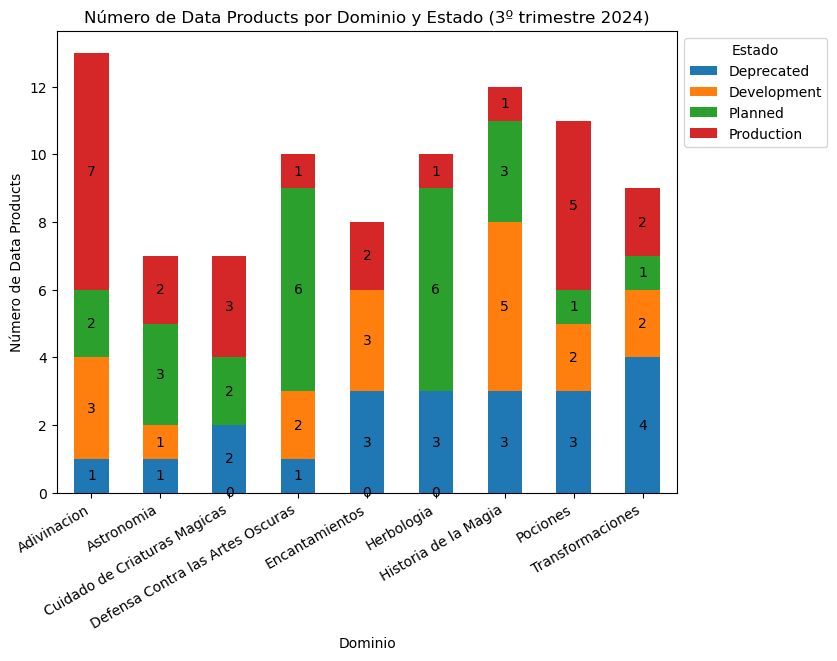

In [136]:
pivot_11 = result_11_df.pivot(index='Domain', columns='Status', values='DataProducts').fillna(0)
ax = pivot_11.plot(kind='bar', stacked=True, figsize=(8,6))
for container in ax.containers:
    ax.bar_label(container, label_type='center')
plt.title('Número de Data Products por Dominio y Estado (3º trimestre 2024)')
plt.xlabel('Dominio')
plt.ylabel('Número de Data Products')
plt.legend(title='Estado', bbox_to_anchor=(1, 1), loc='upper left')
plt.xticks(rotation=30, ha='right')
plt.show()

#### Evolución temporal del número de usuarios de Data Products en producción.
Esta gráfica se construye a partir de una consulta que agrupa el número de usuarios por trimestre, considerando únicamente los Data Products que se encuentran en estado *Production*. El resultado permite visualizar la evolución del uso de los productos en producción a lo largo del año, desde **1034 usuarios** en el primer trimestre, aumentando a **1517** en el segundo trimestre y alcanzando **1617 usuarios** en el tercer trimestre.

Esta tendencia refleja una adopción progresiva de los productos operativos, con un crecimiento destacado entre el primer y segundo trimestre, seguido de estabilización hacia el tercer trimestre. La gráfica permite evaluar el ritmo de crecimiento y el nivel de uso de los productos en producción. 

 * sqlite://
Done.


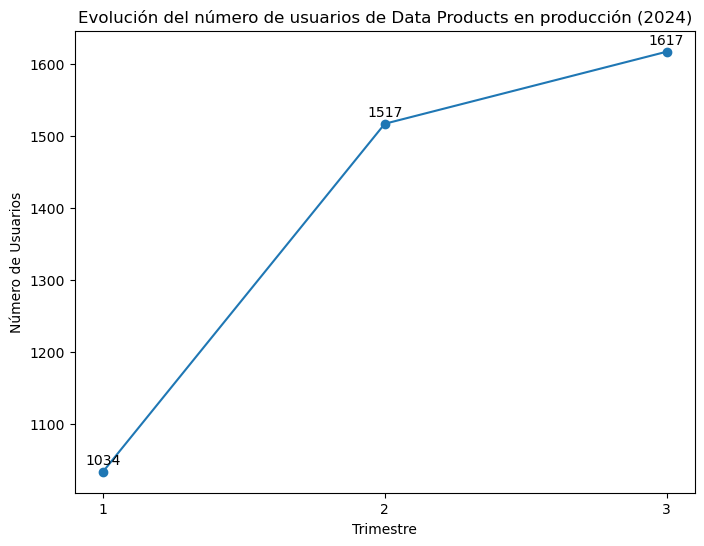

In [137]:
query = """
  SELECT Trimester, 
         SUM(NumberUsers) AS TotalUsers
  FROM trimestres_2024
  WHERE Status = 'Production'
  GROUP BY Trimester; 
"""

graph_data2 = %sql {query}
graph_data2_df = graph_data2.DataFrame()

x = graph_data2_df['Trimester']
y = graph_data2_df['TotalUsers']

plt.figure(figsize=(8,6))
plt.plot( x, y, marker='o')
plt.title('Evolución del número de usuarios de Data Products en producción (2024)')
plt.xlabel('Trimestre')
plt.ylabel('Número de Usuarios')

plt.xticks(x)

for i, value in enumerate(y):
  plt.text(
    x.iloc[i], y.iloc[i] + 10,
    str(value),
    ha='center'
  )

plt.show()

#### Evolución temporal de Data Products totales frente a aquellos que cumplen con compliance.
Esta gráfica se construye a partir de dos consultas:
- La primera consulta contabiliza el número total de Data Products por trimestre
- La segunda filtra aquellos que cumplen con los requisitos de compliance, también agrupados por trimestres

Ambos resultados se representan en la gráfica de líneas, donde la línea azul muestra el total de productos y la línea naranja indica los que cumplen con la normativa. Se observa una evolución positiva en ambos casos:
- El número total de Data Products crece de **50** en el primer trimestre a **70** en el segundo y **87** en el tercero.
- Los productos que cumplen con compliance también aumentan, pasando de **24** a **35** y luego a **43**.

Aunque el la proporción de productos en compliance se mantiene relativamente estable (en torno a la mitad del total), esto implica que la **otra mitad no cumple con los requisitos normativos**. Sería recomendable revisar estos casos y fomentar una mayor alineación con los criterios de compliance, especialmente cuando el volumen de productos está en crecimiento. 

 * sqlite://
Done.
 * sqlite://
Done.


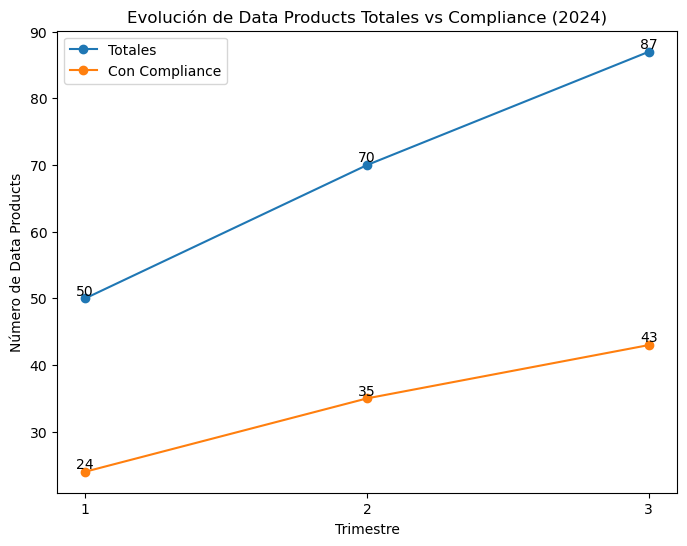

In [24]:
# Total de Data Products por trimestre
query = """
  SELECT Trimester,
         COUNT(ID) AS NumDataProducts
  FROM trimestres_2024
  GROUP BY Trimester;
"""
total_dp = %sql {query}
total_dp_df = total_dp.DataFrame()

# Data Products que cumplen con compliance por trimestre
query_compliance = """
  SELECT Trimester, 
          COUNT(ID) AS NumDataProducts
  FROM trimestres_2024
  WHERE IsCompliance = 1
  GROUP BY Trimester;
"""
compliance_dp = %sql {query_compliance}
compliance_dp_df = compliance_dp.DataFrame()

merged_df = total_dp_df.merge(compliance_dp_df, on='Trimester', suffixes=('_Total', '_Compliance'))
merged_df

x = merged_df['Trimester']

plt.figure(figsize=(8,6))
plt.plot(x, merged_df['NumDataProducts_Total'], marker='o', label='Totales')
plt.plot(x, merged_df['NumDataProducts_Compliance'], marker='o', label='Con Compliance')

plt.title('Evolución de Data Products Totales vs Compliance (2024)')
plt.xlabel('Trimestre')
plt.ylabel('Número de Data Products')
plt.xticks(x)
plt.legend()

for i, value in enumerate(merged_df['NumDataProducts_Total']):
  plt.text(
    x.iloc[i], value + 0.5,
    str(value),
    ha='center'
  )
for i, value in enumerate(merged_df['NumDataProducts_Compliance']):
  plt.text(
    x.iloc[i], value + 0.5,
    str(value),
    ha='center'
  )
plt.show()


#### Evolución temporal del número de Owners por dominio.
Esta gráfica se construye a partir de una consulta que agrupa el número de funcionarios (Owners) únicos por trimestre y dominio. El objetivo es observar cómo varía la cantidad de responsables asignados a cada departamento a lo largo del año.

Tras probar diferentes tipos de visualizaciones, se optó por una gráfica de barras agrupadas, que permite comparar de forma clara los valores por departamento en cada trimestre. Cada barra representa un departamento, y los valores oscilan entre 1 y 3 Owners. Se observa que:
- *Astronomía, Encantamientos, Herbología, Historia de la Magia* y *Transformaciones* se mantienen con **1 funcionario** durante todo el año.
- *Adivinación, Cuidado de Criaturas Mágicas* y *Pociones* mantienen **2 funcionarios** en cada trimestre.
- *Defensa Contra las Artes Oscuras* comienza con **2 funcionarios** en los dos primeros trimestres, pero aumenta a **3** en el tercero.

Esta visualización permite identificar las estructuras en cada departamento. En general, se observa estabilidad, aunque algunos cambios puntuales podrían estar relacionados con ajustes en la carga de trabajo o nuevas necesidades en el departamento.

 * sqlite://
Done.


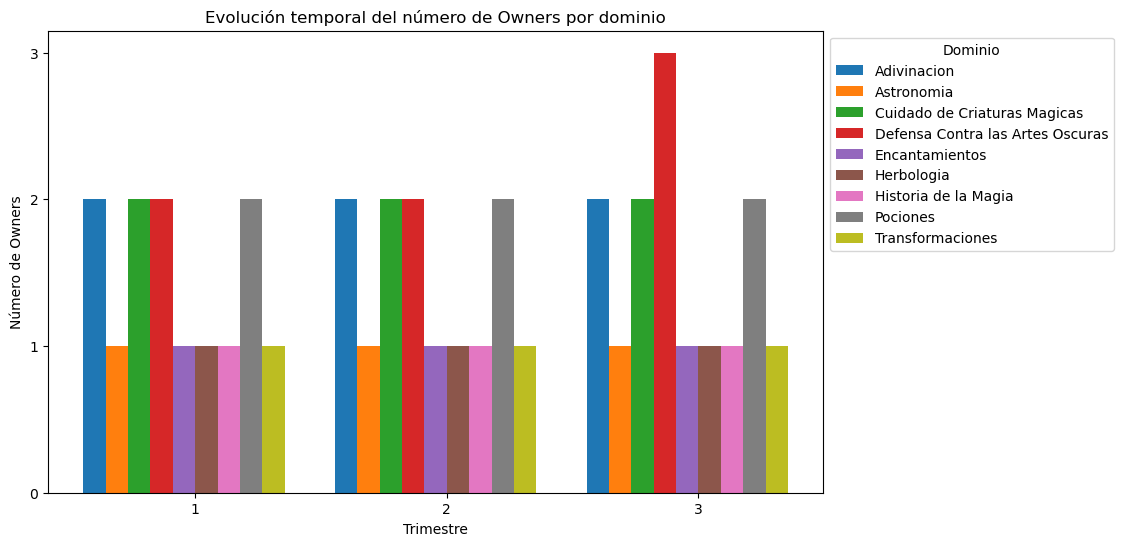

In [143]:
query = """
  SELECT Trimester, Domain,
         COUNT(DISTINCT Owner) AS NumOwners
  FROM trimestres_2024
  GROUP BY Trimester, Domain;
"""
owner_data = %sql {query}
owner_data_df = owner_data.DataFrame()

pivot = owner_data_df.pivot(index='Trimester', columns='Domain', values='NumOwners').fillna(0)
plt.figure(figsize=(10, 6))

x = pivot.index
dominios = pivot.columns
n = len(dominios)
bar_width = 0.8 / n
offset = [ (i - n / 2) * bar_width for i in range(n)]

for offset, dominio in zip(offset, dominios):
    plt.bar(x + offset, pivot[dominio], width=bar_width, label=dominio)
plt.title('Evolución temporal del número de Owners por dominio')
plt.xlabel('Trimestre')
plt.ylabel('Número de Owners')
plt.legend(title='Dominio', bbox_to_anchor=(1, 1), loc='upper left')
plt.xticks(x)
plt.yticks(range(0, pivot.values.max() + 1))
plt.show()

## Conclusiones
El análisis completo de los Data Products de Hogwarts durante los tres trimestres de 2024 muestra un ecosistema en crecimiento, con buena actividad en varios departamentos, pero con áreas críticas que requieren de intervención para garantizar estabilidad, seguridad y cumplimiento de normativas.

**1. Producción de los departamentos:** Los departamentos de *Adivinación* y *Pociones* muestran la mayor cantidad de productos en *Production*, mientras que *Herbología* presenta el mayor número de *Planned*, lo que indica que son departamentos activos y en desarrollo continuo. Por otro lado, *Transformaciones* mantiene la mayor proporción de productos *Deprecated*, lo que puede conllevar riesgos. Es importante destacar que *Herbología* tambien tiene un número elevado de *Deprecated*, por lo que debería mantenerse el trabajo que ya parece estar realizando en compensarlos.

**2. Normativa compliance:** Aunque existe un número considerable de productos que cumplen la normativa compliance, solo representan aproximadamente el 50%, lo cual resulta insuficiente para asegurar un entorno estable y seguro. Además, hay un número elevado de usuario utilizando productos en *Planned y Production* que **no** cumplen la normativa, lo que supone riesgo adicional. Sería necesario revisar estos casos y aplicar las correcciones o migraciones correspondientes.

**3. Tendencia de uso:** En general, la tendencia de uso de los Data Products aumenta de forma progresiva a lo largo del año. Sin embargo, también crece el uso de productos *Deprecated*, llegando a 1171 usuarios en el tercer trimestre, y de productos que no cumplen la normativa compliance. Ambos casos requieren especial atención para evitar problemas futuros, especialmente considerando que la utilización no deja de aumentar.

**4. Funcionarios y carga de trabajo:** El análisis muestra una distribución del trabajo generalmente equilibrada entre funcionarios. No obstante, *Severus Snape* es el único que trabaja en más de un departamento, lo que podría explicar su presencia en la lista de funcionarios menos productivos debido a una posible sobrecarga. Además, sería recomendable hacer un seguimiento de los funcionarios con mayor porcentaje de *Deprecated*, como *Wilhelmina Grubbly-Plank*, que llega a superar el 50%.
